Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,0,1)[24] intercept   : AIC=inf, Time=8.47 sec
 ARIMA(0,0,0)(0,0,0)[24] intercept   : AIC=5914.305, Time=0.03 sec
 ARIMA(1,0,0)(1,0,0)[24] intercept   : AIC=1393.071, Time=1.92 sec
 ARIMA(0,0,1)(0,0,1)[24] intercept   : AIC=3225.032, Time=2.21 sec
 ARIMA(0,0,0)(0,0,0)[24]             : AIC=5914.846, Time=0.01 sec
 ARIMA(1,0,0)(0,0,0)[24] intercept   : AIC=1927.941, Time=0.12 sec
 ARIMA(1,0,0)(2,0,0)[24] intercept   : AIC=1275.872, Time=10.64 sec
 ARIMA(1,0,0)(2,0,1)[24] intercept   : AIC=inf, Time=26.21 sec
 ARIMA(1,0,0)(1,0,1)[24] intercept   : AIC=inf, Time=5.64 sec
 ARIMA(0,0,0)(2,0,0)[24] intercept   : AIC=4970.691, Time=3.99 sec
 ARIMA(2,0,0)(2,0,0)[24] intercept   : AIC=540.503, Time=15.75 sec
 ARIMA(2,0,0)(1,0,0)[24] intercept   : AIC=624.586, Time=2.24 sec
 ARIMA(2,0,0)(2,0,1)[24] intercept   : AIC=inf, Time=28.98 sec
 ARIMA(2,0,0)(1,0,1)[24] intercept   : AIC=inf, Time=7.65 sec
 ARIMA(3,0,0)(2,0,0)[24] intercept   : AIC

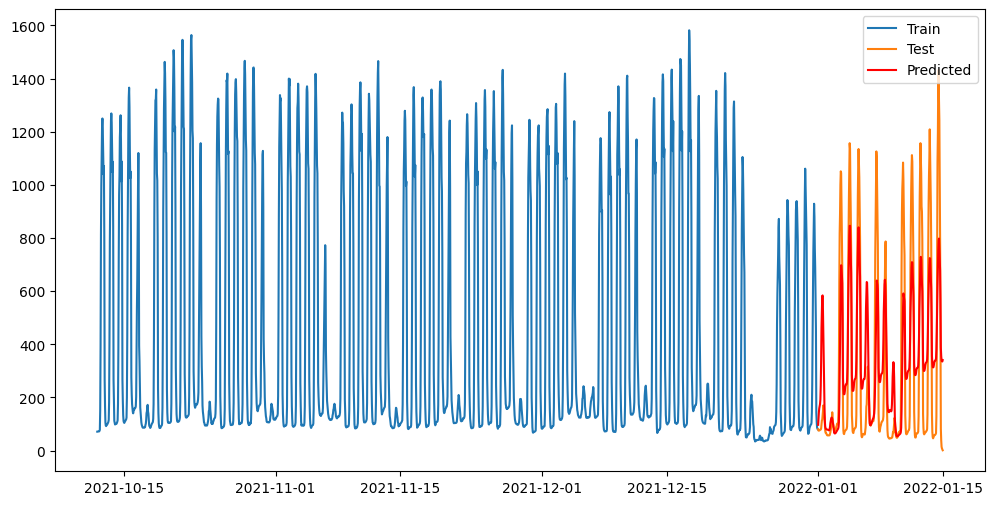

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pmdarima import auto_arima
from datetime import datetime

# Load the dataset
df = pd.read_csv('../preprocess/parking_time_series_with_features_1_hour.csv', delimiter=',')

# Parse the 'Time' column to datetime and set it as index
df['Time'] = pd.to_datetime(df['Time'])
df.set_index('Time', inplace=True)
df.sort_index(inplace=True)


# Convert exogenous features to appropriate data types
df['day_of_year'] = df['day_of_year'].astype(int)
df['weekday'] = df['weekday'].astype(int)
df['hour'] = df['hour'].astype(int)
df['is_holiday'] = df['is_holiday'].astype(int)

exogenous_features = ["day_of_year", "weekday", "hour", "is_holiday"]

# Make the time series data stationary using rolling mean and standard deviation
rolling_window = 24  # 24-hour window for hourly data
df['Parkings_rolling_mean'] = df['Parkings'].rolling(window=rolling_window).mean()
df['Parkings_rolling_std'] = df['Parkings'].rolling(window=rolling_window).std()
df['Parkings_stationary'] = (df['Parkings'] - df['Parkings_rolling_mean']) / df['Parkings_rolling_std']

# Drop NaN values resulting from rolling calculations
df.dropna(inplace=True)

# Split the data into training and test sets
end_date = datetime(2022, 1, 1)
train_data = df[df.index < end_date]
test_data = df[df.index >= end_date]

# Ensure the training data index has a frequency set
train_data.index = pd.DatetimeIndex(train_data.index.values, freq='h')  # 'h' stands for hourly frequency

# Extract exogenous features for training and test sets
train_exog = train_data[exogenous_features]
test_exog = test_data[exogenous_features]

# Perform auto_arima to find the best model parameters
auto_arima_model = auto_arima(train_data['Parkings_stationary'], 
                              exogenous=train_exog, 
                              seasonal=True, 
                              m=24,  # Daily seasonality in hourly data
                              trace=True,
                              error_action='ignore', 
                              suppress_warnings=True,
                              stepwise=True)

# Fit the best model found by auto_arima on the training data
auto_arima_model.fit(train_data['Parkings_stationary'], exogenous=train_exog)

# Predict using the fitted model with exogenous features
predictions_stationary = auto_arima_model.predict(n_periods=len(test_data), exogenous=test_exog)

# Invert the transformations to return to the original scale
predictions_rolling_mean_reversed = predictions_stationary * test_data['Parkings_rolling_std'] + test_data['Parkings_rolling_mean']

# Plot the actual vs predicted values
plt.figure(figsize=(12, 6))
plt.plot(train_data.index, train_data['Parkings'], label='Train')
plt.plot(test_data.index, test_data['Parkings'], label='Test')
plt.plot(test_data.index, predictions_rolling_mean_reversed, label='Predicted', color='red')
plt.legend()
plt.show()


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pmdarima import auto_arima
from datetime import datetime

# Load the dataset
df = pd.read_csv('../preprocess/parking_time_series_with_features_1.csv', delimiter=',')

# Parse the 'Time' column to datetime and set it as index
df['Time'] = pd.to_datetime(df['Time'])
df.set_index('Time', inplace=True)
df.sort_index(inplace=True)

# Downsample the data to hourly frequency
df = df.resample('h').mean()

# Convert exogenous features to appropriate data types
df['day_of_year'] = df['day_of_year'].astype(int)
df['weekday'] = df['weekday'].astype(int)
df['hour'] = df['hour'].astype(int)
df['is_holiday'] = df['is_holiday'].astype(int)

exogenous_features = ["day_of_year", "weekday", "hour", "is_holiday"]

# Make the time series data stationary using rolling mean and standard deviation
rolling_window = 24  # 24-hour window for hourly data
df['Parkings_rolling_mean'] = df['Parkings'].rolling(window=rolling_window).mean()
df['Parkings_rolling_std'] = df['Parkings'].rolling(window=rolling_window).std()
df['Parkings_stationary'] = (df['Parkings'] - df['Parkings_rolling_mean']) / df['Parkings_rolling_std']

# Drop NaN values resulting from rolling calculations
df.dropna(inplace=True)

# Split the data into training and test sets
end_date = datetime(2022, 1, 1)
train_data = df[df.index < end_date]
test_data = df[df.index >= end_date]

# Ensure the training data index has a frequency set
train_data.index = pd.DatetimeIndex(train_data.index.values, freq='h')  # 'h' stands for hourly frequency

# Extract exogenous features for training and test sets
train_exog = train_data[exogenous_features]
test_exog = test_data[exogenous_features]

# Perform auto_arima to find the best model parameters
auto_arima_model = auto_arima(train_data['Parkings_stationary'], 
                              exogenous=train_exog, 
                              seasonal=True, 
                              m=24,  # Daily seasonality in hourly data
                              trace=True,
                              error_action='ignore', 
                              suppress_warnings=True,
                              stepwise=True)

# Fit the best model found by auto_arima on the training data
auto_arima_model.fit(train_data['Parkings_stationary'], exogenous=train_exog)

# Predict using the fitted model with exogenous features
predictions_stationary = auto_arima_model.predict(n_periods=len(test_data), exogenous=test_exog)

# Invert the transformations to return to the original scale
predictions_rolling_mean_reversed = predictions_stationary * test_data['Parkings_rolling_std'] + test_data['Parkings_rolling_mean']

# Plot the actual vs predicted values
plt.figure(figsize=(12, 6))
plt.plot(train_data.index, train_data['Parkings'], label='Train')
plt.plot(test_data.index, test_data['Parkings'], label='Test')
plt.plot(test_data.index, predictions_rolling_mean_reversed, label='Predicted', color='red')
plt.legend()
plt.show()
